# Geospatial Analysis: Is This Pattern Clustered?

Today's question: **In the 1854 Soho cholera outbreak, were deaths clustered? And if so, clustered around what?**

We'll answer it with **Monte Carlo tests**, the same logic as simulating the null in the inference lectures:

1. Pick a **statistic** that measures what you care about
2. Pick a **null process**: how the points would be placed if nothing interesting were going on
3. **Simulate** the null many times and compute the statistic each time
4. **Compare** the observed statistic to the simulated ones

The punchline: **the null you choose changes the conclusion.**

On your own (end of notebook): how the study region changes the answer, nearest neighbors beyond the first, and which pump is closest to each death.

Tools: `numpy`, `scipy`, `geopandas`, `libpysal` (for the data)

## Contents

Reminder: In JupyterLab, the table of contents sidebar, the bulleted-list icon on the left, shows the same outline and highlights the section you're in.

- [1. Setup](#s1)
- [2. The Data: Cholera in Soho, 1854](#s2)
- [3. Measuring Clustering: Average Nearest Neighbor](#s3) · [3a. Three Patterns](#s3a) · [3b. The Cholera Deaths](#s3b)
- [4. Monte Carlo Test #1: Compared to Complete Spatial Randomness](#s4)
- [5. Monte Carlo Test #2: A Better Null](#s5)
- [6. Monte Carlo Test #3: A Sharper Question](#s6)
- [7. Summary](#s7)
- [8. On Your Own](#s8) · [8a. The Study Region Matters](#s8a) · [8b. Beyond the First Neighbor](#s8b) · [8c. Which Pump Is Closest?](#s8c)

## 1. Setup <a id="s1"></a>

In [ ]:
# if you don't have these installed, uncomment and run once
# %pip install --user --no-deps libpysal

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import libpysal as ps
from scipy.spatial import cKDTree

import seaborn as sns
sns.set_theme(style="white",
              font_scale=1.5,
              rc={'axes.spines.right': False, 'axes.spines.top': False})

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (12, 6)

#improve resolution
#comment this line if erroring on your machine/screen
%config InlineBackend.figure_format ='retina'

import warnings
warnings.filterwarnings('ignore')

# so everyone gets the same "random" simulations
rng = np.random.default_rng(108)

## 2. The Data: Cholera in Soho, 1854 <a id="s2"></a>

In late August 1854, cholera broke out in Soho, London. Most doctors at the time thought cholera spread through "bad air." John Snow suspected contaminated water, mapped where people died, and pointed to a public water pump on Broad Street. On September 8 he persuaded local officials to remove the pump's handle.

His map is one of the most famous in data science. `libpysal` includes a digitized version of it:

- **people**: 324 locations; `Count` is the number of cholera deaths recorded at each one (many are 0)
- **pumps**: the 13 public water pumps
- **streets**: the street network

In [2]:
people = gpd.read_file(ps.examples.get_path('SohoPeople.shp'))
pumps = gpd.read_file(ps.examples.get_path('SohoWater.shp'))
streets = gpd.read_file(ps.examples.get_path('Soho_Network.shp'))

people.head()

,Id,Count,geometry
0,0,1,POINT (-15539.921 6712903.938)
1,0,3,POINT (-15356.721 6712858.073)
2,0,2,POINT (-15336.09 6712866.374)
3,0,1,POINT (-15353.877 6713017.559)
4,0,0,POINT (-15282.597 6712895.684)


The coordinates are stored in **web Mercator** (`EPSG:3857`), the projection behind most online maps. Web Mercator stretches distances away from the equator: at London's latitude, 100 "map meters" is only about 62 real meters.

We're about to measure distances, so we'll **reproject** to the British National Grid (`EPSG:27700`), a projected coordinate reference system (CRS) whose units are real meters.

In [3]:
print('before:', people.crs)

people = people.to_crs(epsg=27700)
pumps = pumps.to_crs(epsg=27700)
streets = streets.to_crs(epsg=27700)

print('after: ', people.crs)

before: EPSG:3857
after:  EPSG:27700


In [4]:
# pull out plain numpy arrays of x/y coordinates (in meters) for the analysis
xy = np.column_stack([people.geometry.x, people.geometry.y])
deaths = people['Count'].to_numpy()
pump_xy = np.column_stack([pumps.geometry.x, pumps.geometry.y])

# the Broad Street pump
broad_street = pump_xy[8]

# the locations with at least one death: this is our point pattern
death_xy = xy[deaths > 0]

print(f'{deaths.sum()} deaths at {len(death_xy)} locations; {(deaths == 0).sum()} locations with no deaths')

392 deaths at 133 locations; 191 locations with no deaths


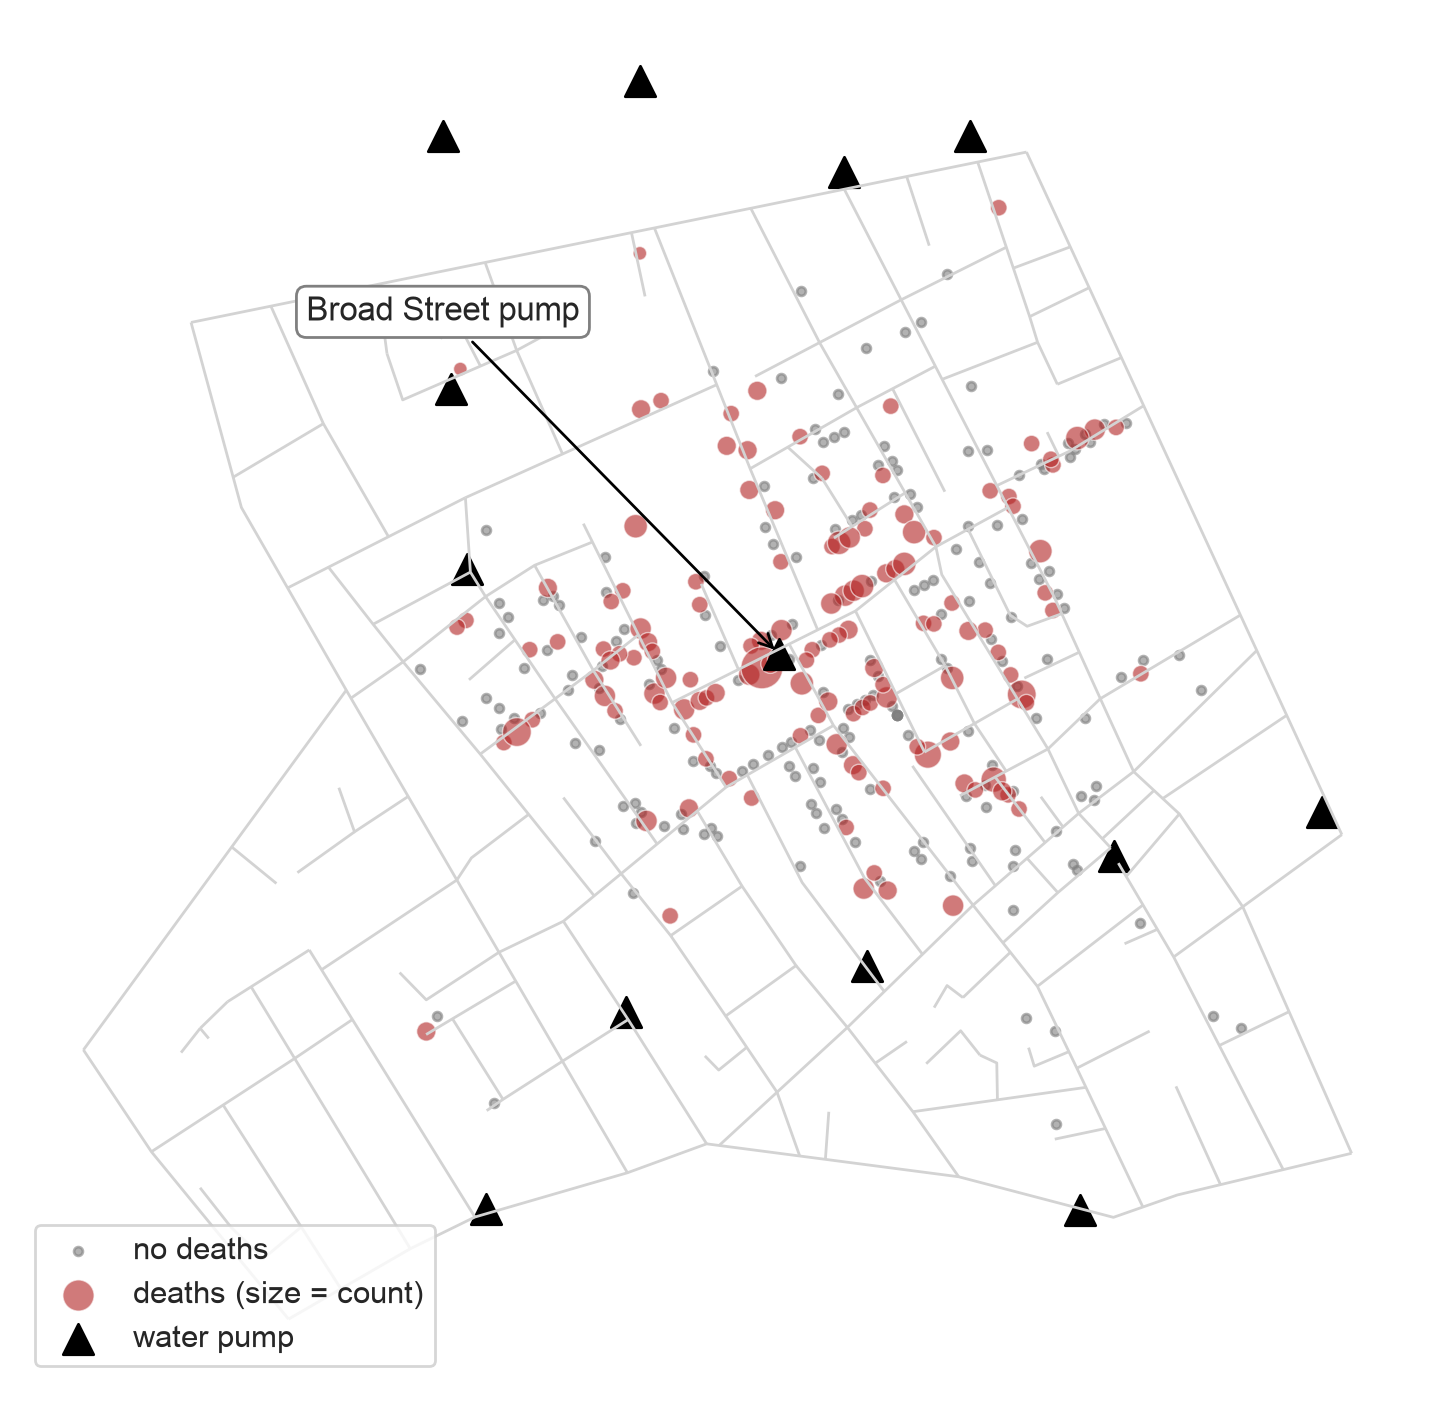

In [5]:
def plot_soho(ax=None):
    '''Draw the streets, the death locations (sized by count) and the pumps.'''
    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 9))
    streets.plot(ax=ax, color='lightgray', linewidth=1)
    ax.scatter(xy[deaths == 0, 0], xy[deaths == 0, 1],
               s=10, color='gray', alpha=0.6, label='no deaths')
    ax.scatter(death_xy[:, 0], death_xy[:, 1],
               s=12 + 12 * deaths[deaths > 0], color='firebrick', alpha=0.6,
               edgecolor='white', linewidth=0.5, label='deaths (size = count)')
    ax.scatter(pump_xy[:, 0], pump_xy[:, 1], marker='^', s=120,
               color='black', label='water pump')
    ax.annotate('Broad Street pump', broad_street, xytext=(-170, 120),
                textcoords='offset points', fontsize=12,
                bbox=dict(boxstyle='round', facecolor='white', edgecolor='gray'),
                arrowprops=dict(arrowstyle='->', color='black'))
    ax.set_axis_off()
    ax.set_aspect('equal')
    ax.legend(loc='lower left', fontsize=11)
    return ax

plot_soho();

It *looks* clustered. But people are bad at judging randomness by eye: truly random points almost always look like they have clumps. Let's measure it.

## 3. Measuring Clustering: Average Nearest Neighbor <a id="s3"></a>

**Average nearest neighbor (ANN)**: for each point, find the distance to the closest other point, then average those distances.

- **Small ANN**: points sit close to one another (clustered)
- **Large ANN**: points are spread out evenly (dispersed)

`scipy`'s `cKDTree` finds nearest neighbors quickly. We ask for `k=2` neighbors because each point's closest neighbor is itself, at distance 0.

In [6]:
def ann(points):
    '''Average distance from each point to its nearest neighbor.'''
    distances, _ = cKDTree(points).query(points, k=2)
    return distances[:, 1].mean()

### 3a. Three Patterns <a id="s3a"></a>

Before the real data, here are three made-up patterns of 100 points in a 100 × 100 square.

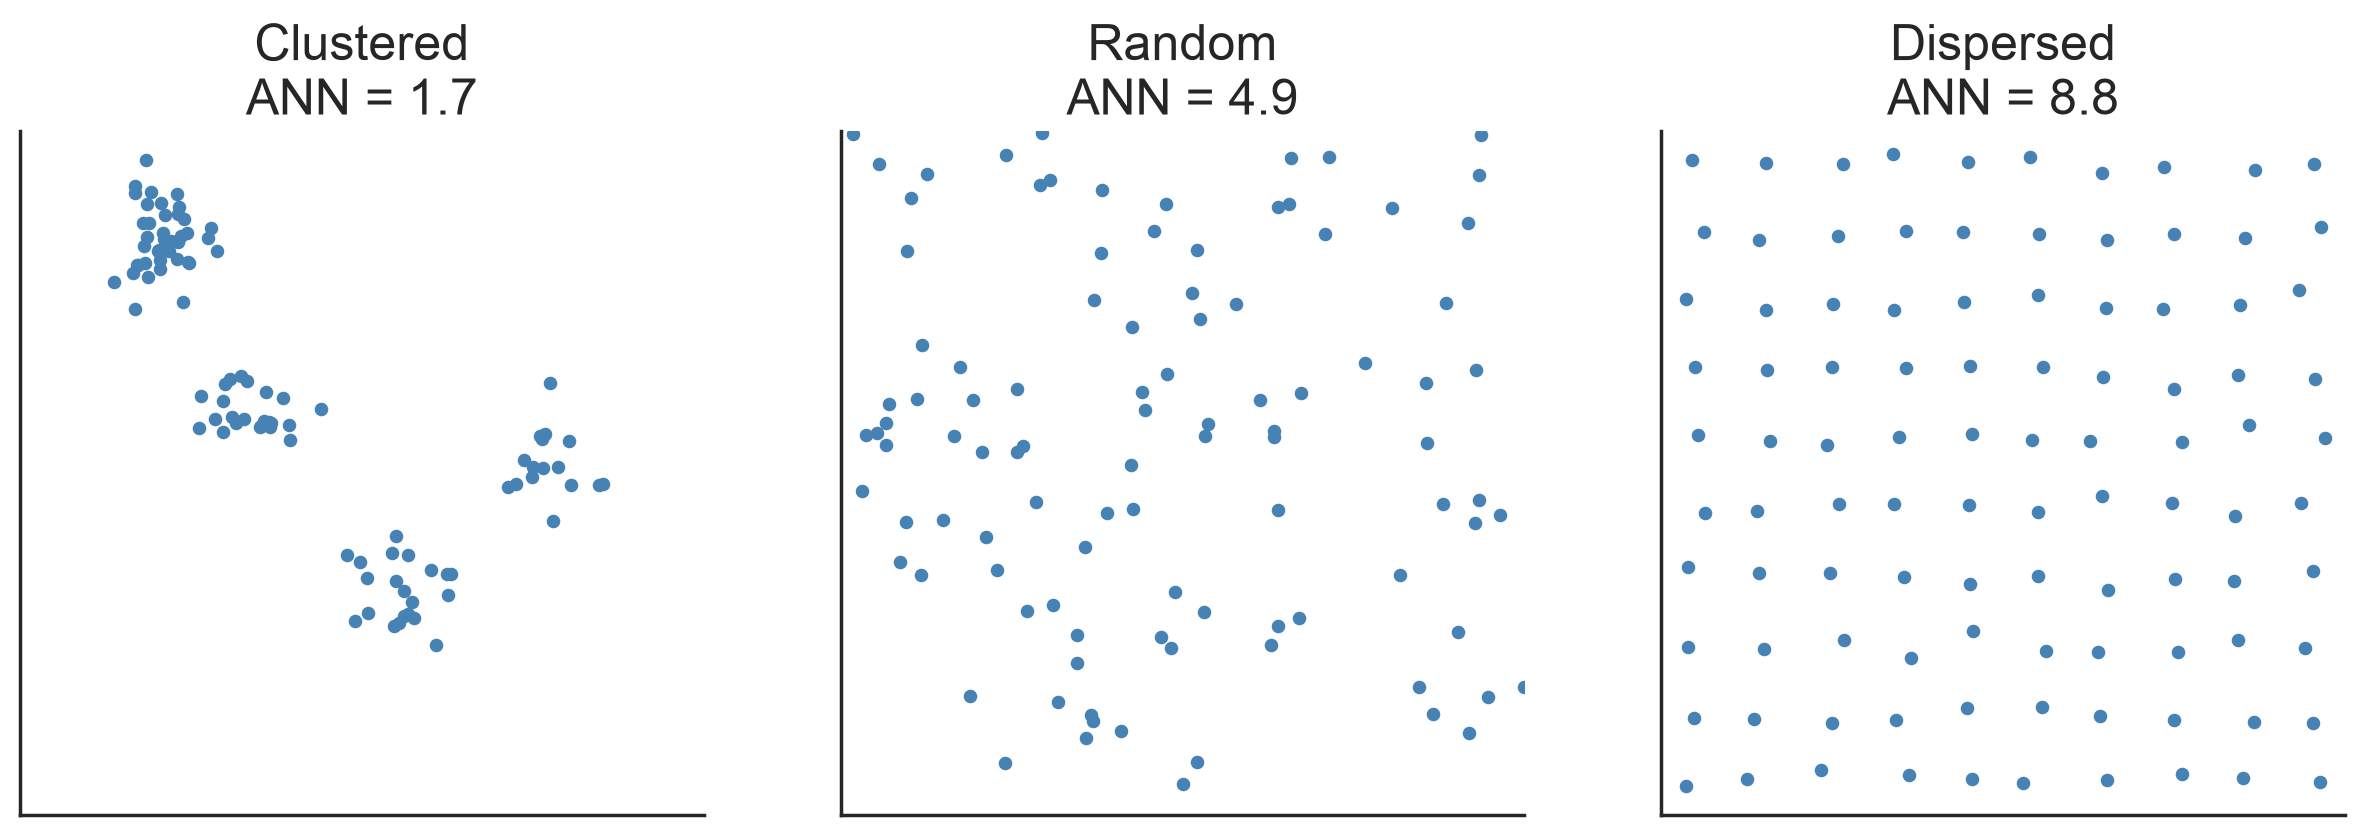

In [7]:
n = 100

# random: every location equally likely, each point placed independently
random_pts = rng.uniform(0, 100, size=(n, 2))

# clustered: points scattered around 5 centers
centers = rng.uniform(15, 85, size=(5, 2))
clustered_pts = centers[rng.integers(0, 5, n)] + rng.normal(0, 4, size=(n, 2))

# dispersed: a grid, slightly jittered
grid = np.arange(5, 100, 10)
gx, gy = np.meshgrid(grid, grid)
dispersed_pts = np.column_stack([gx.ravel(), gy.ravel()]) + rng.normal(0, 1, size=(n, 2))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, pts, name in zip(axes, [clustered_pts, random_pts, dispersed_pts],
                         ['Clustered', 'Random', 'Dispersed']):
    ax.scatter(pts[:, 0], pts[:, 1], s=15, color='steelblue')
    ax.set_title(f'{name}\nANN = {ann(pts):.1f}')
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

ANN goes up from clustered to random to dispersed. But a number on its own doesn't tell us much: whether an ANN is "small" depends on how many points there are and how big the region is. That's why we need a comparison.

### 3b. The Cholera Deaths <a id="s3b"></a>

In [8]:
observed_ann = ann(death_xy)
print(f'ANN for the {len(death_xy)} death locations: {observed_ann:.1f} meters')

ANN for the 133 death locations: 17.1 meters


## 4. Monte Carlo Test #1: Compared to Complete Spatial Randomness <a id="s4"></a>

- **Statistic:** ANN of the death locations
- **Null process: complete spatial randomness (CSR).** Every location in the study region is equally likely, and each point is placed independently of the others.
    - H<sub>0</sub>: the death locations are consistent with CSR
    - H<sub>a</sub>: they're more clustered than CSR (smaller ANN)
- **Study region:** the rectangle that just contains all 324 locations

We place the same number of points (133) uniformly at random in the rectangle, compute ANN, and repeat 999 times.

In [9]:
xmin, ymin = xy.min(axis=0)
xmax, ymax = xy.max(axis=0)
n_points = len(death_xy)
n_sims = 999

def simulate_csr():
    '''One realization of CSR: n_points placed uniformly at random in the study region.'''
    x = rng.uniform(xmin, xmax, n_points)
    y = rng.uniform(ymin, ymax, n_points)
    return np.column_stack([x, y])

csr_anns = np.array([ann(simulate_csr()) for _ in range(n_sims)])

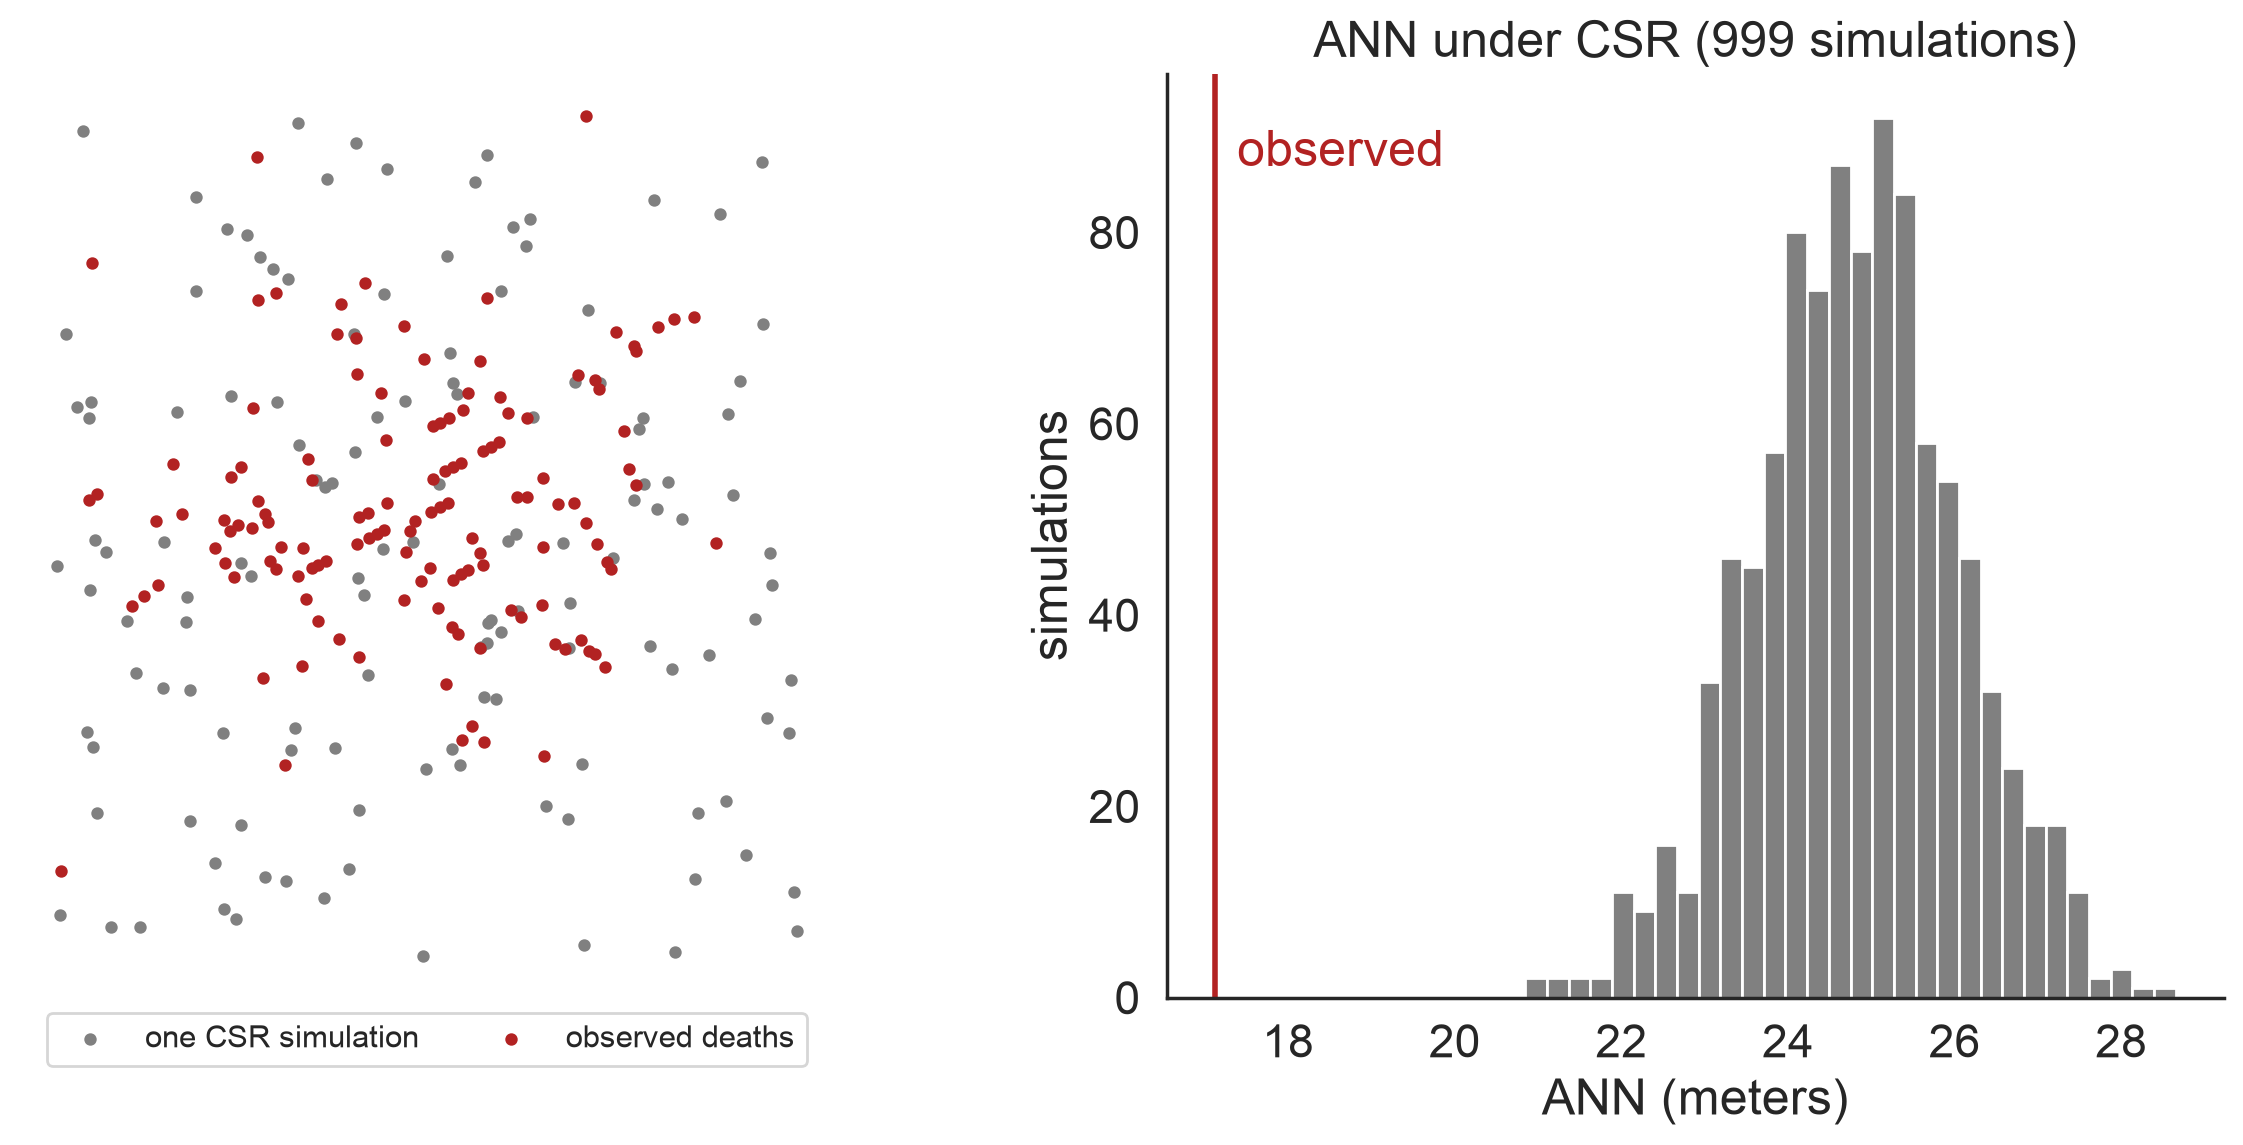

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# left: one simulated CSR pattern next to the observed one
axes[0].scatter(*simulate_csr().T, s=12, color='gray', label='one CSR simulation')
axes[0].scatter(*death_xy.T, s=12, color='firebrick', label='observed deaths')
axes[0].set_aspect('equal')
axes[0].set_axis_off()
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, 0), ncol=2, fontsize=11)

# right: the simulated ANNs and where the observed value falls
axes[1].hist(csr_anns, bins=30, color='gray', edgecolor='white')
axes[1].axvline(observed_ann, color='firebrick', linewidth=2)
axes[1].annotate('observed', (observed_ann, axes[1].get_ylim()[1] * 0.9),
                 xytext=(8, 0), textcoords='offset points', color='firebrick')
axes[1].set_xlabel('ANN (meters)')
axes[1].set_ylabel('simulations')
axes[1].set_title('ANN under CSR (999 simulations)');

**p-value** = the proportion of simulations at least as extreme as what we observed. We add 1 to the top and bottom to count the observed pattern as one of the possibilities, so the p-value can never be exactly 0.

In [11]:
def mc_p_value(observed, simulated):
    '''One-sided Monte Carlo p-value: how often is a simulated value <= the observed one?'''
    return (np.sum(simulated <= observed) + 1) / (len(simulated) + 1)

print(f'smallest simulated ANN: {csr_anns.min():.1f} m; observed: {observed_ann:.1f} m')
print(f'p = {mc_p_value(observed_ann, csr_anns):.3f}')

smallest simulated ANN: 20.8 m; observed: 17.1 m
p = 0.001


#### Question #4

<img src="QRCodes/15_01.png" width="300" align="right">

None of the 999 CSR simulations had an ANN as small as the observed one (p = 0.001). What can we conclude?

- A) Contaminated water caused the deaths
- B) The death locations are more clustered than points scattered completely at random over the study region
- C) There's a 0.1% chance the deaths are randomly distributed
- D) The Broad Street pump is at the center of the cluster

Poll: https://forms.gle/tQB6bUQRQjYrtXGb9


## 5. Monte Carlo Test #2: A Better Null <a id="s5"></a>

Look back at the map. Points under CSR land anywhere in the rectangle: in the middle of streets, in squares and yards, in the empty corners. **People don't live everywhere,** and the places they do live are clustered along streets.

Sound familiar? This is the bank-robbery problem from the slides (**nonuniformity**): bank robberies are clustered because banks are clustered.

A better null: **deaths happen at random among the 324 locations in the data.** We pick 133 of the 324 locations at random (without replacement), compute ANN, and repeat. This is the same idea as a permutation test: shuffle which locations had deaths.

In [12]:
def simulate_locations():
    '''One realization of the null: 133 of the 324 locations, chosen at random.'''
    chosen = rng.choice(len(xy), size=n_points, replace=False)
    return xy[chosen]

location_anns = np.array([ann(simulate_locations()) for _ in range(n_sims)])

print(f'p = {mc_p_value(observed_ann, location_anns):.3f}')

p = 0.305


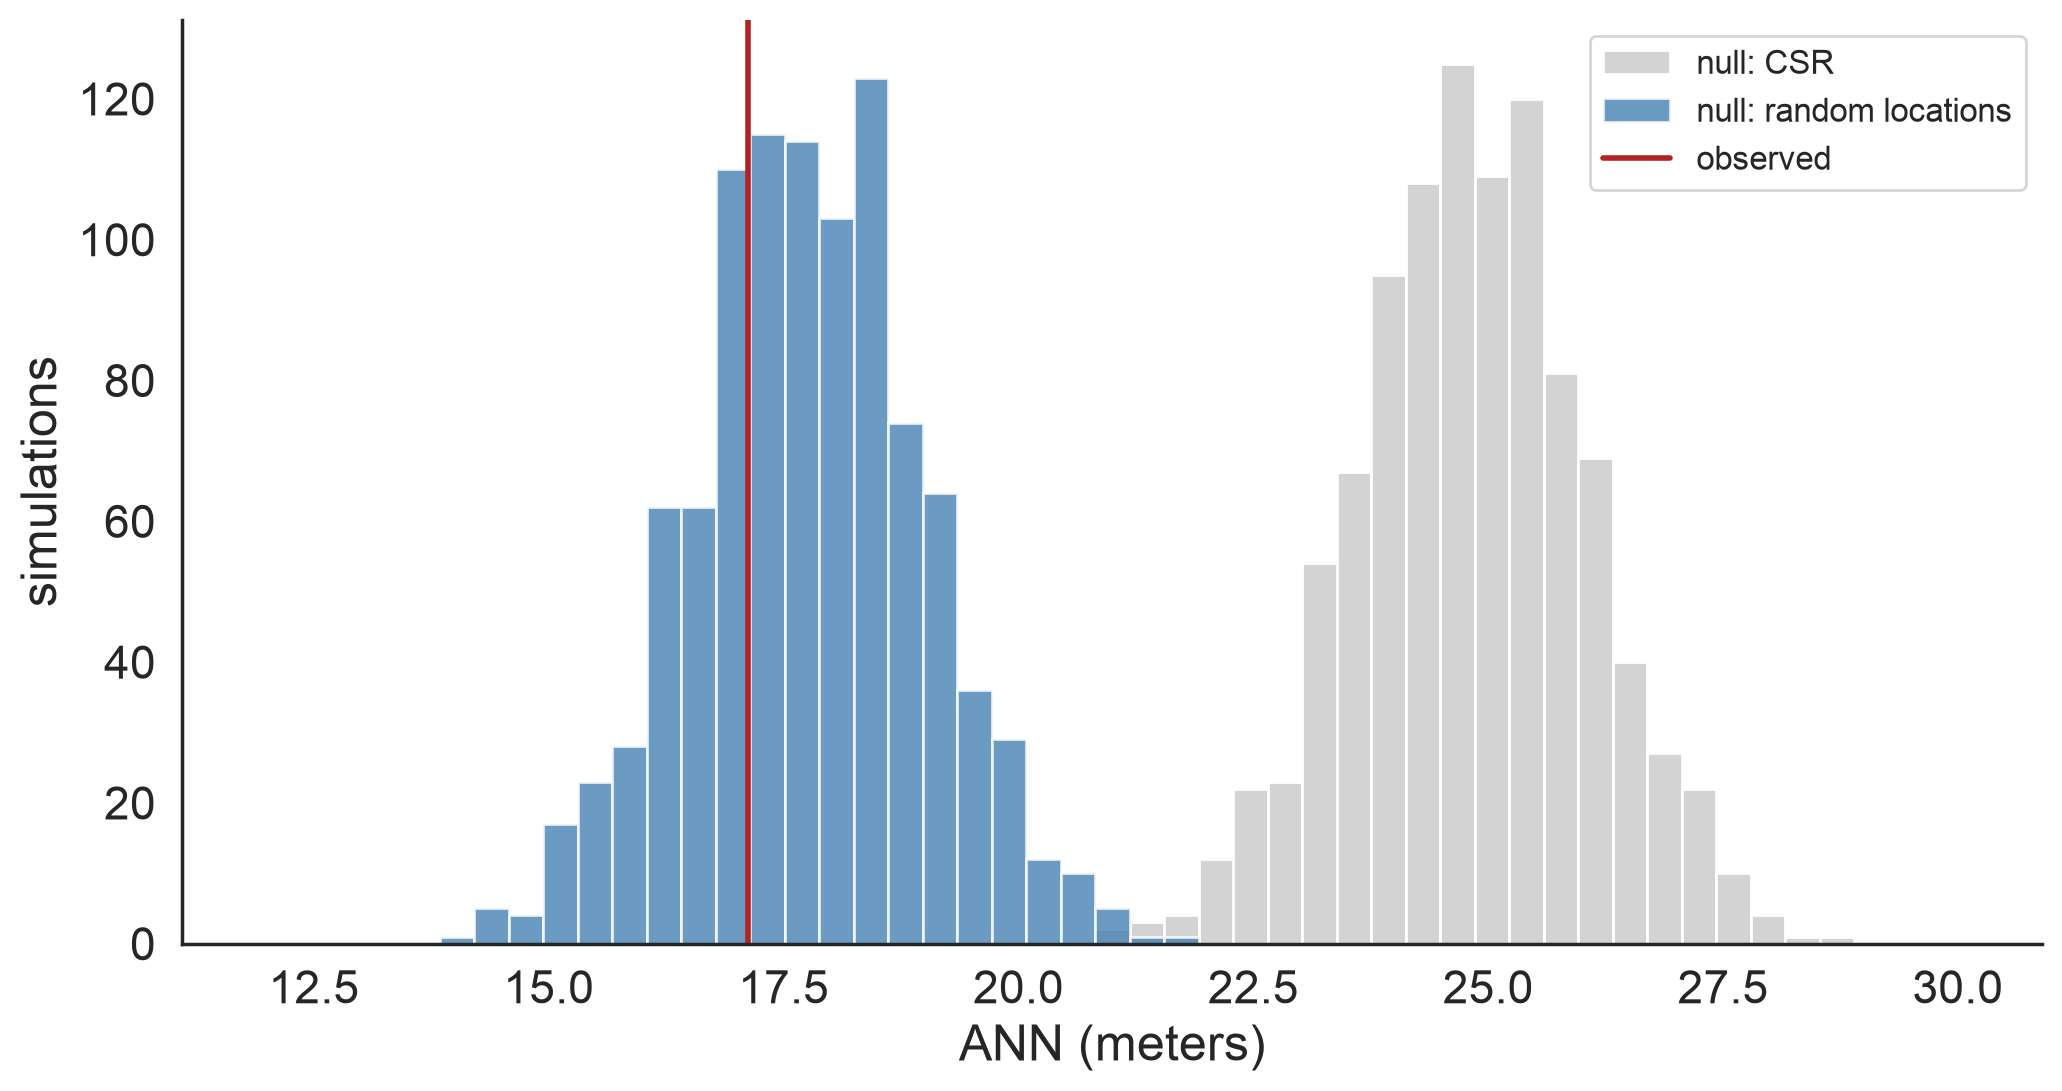

In [13]:
fig, ax = plt.subplots()
bins = np.linspace(12, 30, 50)
ax.hist(csr_anns, bins=bins, color='lightgray', edgecolor='white', label='null: CSR')
ax.hist(location_anns, bins=bins, color='steelblue', edgecolor='white', alpha=0.8,
        label='null: random locations')
ax.axvline(observed_ann, color='firebrick', linewidth=2, label='observed')
ax.set_xlabel('ANN (meters)')
ax.set_ylabel('simulations')
ax.legend(fontsize=12);

Same data, same statistic, **different null, different conclusion.** Compared to random spots on the map, the deaths are very clustered. Compared to the places where people actually were, they aren't unusually clustered (p ≈ 0.3).

Failing to reject doesn't prove the deaths were random. It means ANN can't tell them apart from a random set of locations.

One caveat: the 324 locations are the ones recorded in this dataset, not a full count of every home in Soho or how many people lived in each.

#### Question #5

<img src="QRCodes/15_01.png" width="300" align="right">

The CSR test said "clustered" (p = 0.001), and the random-locations test said "not unusually clustered" (p ≈ 0.3). Which problem from the slides best explains why they disagree?

- A) Spatial autocorrelation
- B) MAUP
- C) Edge effects
- D) Ecological fallacy
- E) Nonuniformity

Poll: https://forms.gle/tQB6bUQRQjYrtXGb9


## 6. Monte Carlo Test #3: A Sharper Question <a id="s6"></a>

ANN asks a vague question: are the deaths close to *each other*? Snow's question was more specific: are the deaths close to **the Broad Street pump**?

- **Statistic:** the average distance from a death to the Broad Street pump (each location counted once per death)
- **Null:** the same deaths, shuffled at random among the 324 locations

In [14]:
dist_to_broad = np.linalg.norm(xy - broad_street, axis=1)

# weighted average: a location with 5 deaths counts 5 times
observed_dist = np.average(dist_to_broad, weights=deaths)

# shuffle the death counts across locations, recompute, repeat
shuffled_dists = np.array([np.average(dist_to_broad, weights=rng.permutation(deaths))
                           for _ in range(n_sims)])

print(f'observed average distance to the Broad Street pump: {observed_dist:.0f} m')
print(f'shuffled deaths: {shuffled_dists.mean():.0f} m on average '
      f'(closest of {n_sims}: {shuffled_dists.min():.0f} m)')
print(f'p = {mc_p_value(observed_dist, shuffled_dists):.3f}')

observed average distance to the Broad Street pump: 111 m
shuffled deaths: 133 m on average (closest of 999: 117 m)
p = 0.001


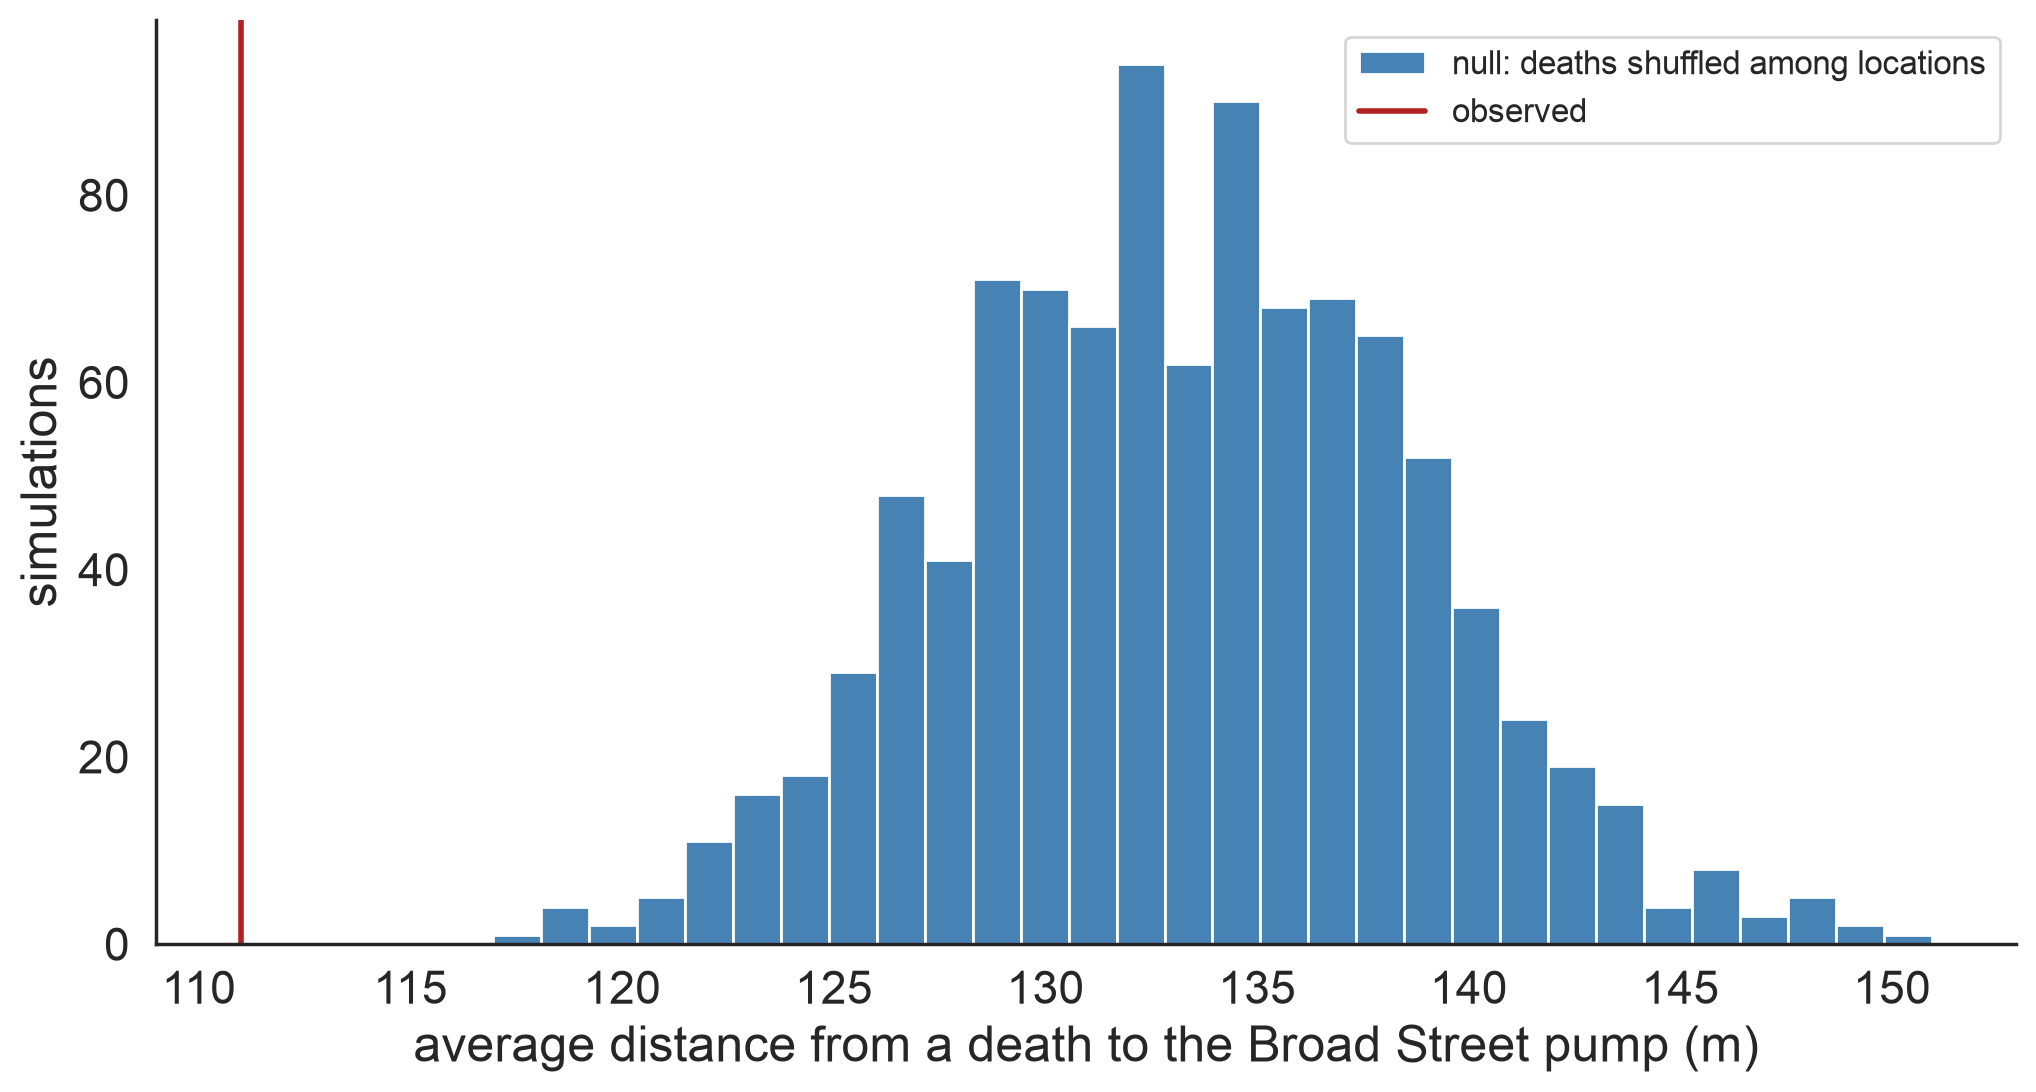

In [15]:
fig, ax = plt.subplots()
ax.hist(shuffled_dists, bins=30, color='steelblue', edgecolor='white',
        label='null: deaths shuffled among locations')
ax.axvline(observed_dist, color='firebrick', linewidth=2, label='observed')
ax.set_xlabel('average distance from a death to the Broad Street pump (m)')
ax.set_ylabel('simulations')
ax.legend(fontsize=12);

The deaths are much closer to the Broad Street pump than the same number of deaths spread among the same locations would be. This time, the population-based null doesn't explain the pattern away.

What this does and doesn't show:
- It **does** show that deaths were concentrated near that pump, beyond what the layout of the neighborhood explains.
- It **doesn't** show the pump *caused* the deaths. Anything else concentrated near Broad Street would produce the same pattern. Snow made the causal case with other evidence too: for example, nearby workers at a brewery, who drank beer and the brewery's own well water, mostly didn't get sick.

## 7. Summary <a id="s7"></a>

1. **Your eyes aren't a test.** Random points look clumpy. Measure, then compare.
2. **A Monte Carlo test:** pick a statistic → pick a null process → simulate it many times → see where the observed value falls. p = (# as or more extreme + 1) / (# simulations + 1).
3. **The null is a modeling choice, and it changes the conclusion.** CSR ignores where people (or banks, or stores) actually are. A population-based null often makes more sense.
4. **Ask a specific question.** "Clustered around the pump?" found a pattern that "clustered at all?" missed.
5. **The study region is a choice too** (edge effects). See [8a](#s8a).
6. **A spatial pattern isn't a cause.** It tells you where to look next.

## 8. On Your Own <a id="s8"></a>

We won't get to these in lecture.

### 8a. The Study Region Matters <a id="s8a"></a>

Our CSR test used the rectangle around all 324 locations. What if we'd used the rectangle around just the 133 death locations? A smaller region packs the simulated points closer together, so CSR's ANN shrinks.

This is the **edge effect** from the slides: where you draw the boundary changes the answer.

Here the conclusion holds either way (p = 0.001 both times), but the CSR distribution moves a lot.

In [ ]:
dxmin, dymin = death_xy.min(axis=0)
dxmax, dymax = death_xy.max(axis=0)

def simulate_csr_tight():
    x = rng.uniform(dxmin, dxmax, n_points)
    y = rng.uniform(dymin, dymax, n_points)
    return np.column_stack([x, y])

tight_anns = np.array([ann(simulate_csr_tight()) for _ in range(n_sims)])

area_all = (xmax - xmin) * (ymax - ymin)
area_tight = (dxmax - dxmin) * (dymax - dymin)
print(f'region area: {area_all:,.0f} m² (all locations) vs {area_tight:,.0f} m² (death locations only)')
print(f'average CSR ANN: {csr_anns.mean():.1f} m vs {tight_anns.mean():.1f} m')
print(f'p = {mc_p_value(observed_ann, csr_anns):.3f} vs {mc_p_value(observed_ann, tight_anns):.3f}')

Try it: make the region much *bigger* (say, add 500 m on every side). What happens to the CSR ANN and the p-value? What does that tell you about a test that "finds clustering" in a study region drawn much bigger than where the points could be?

### 8b. Beyond the First Neighbor <a id="s8b"></a>

ANN uses only each point's *closest* neighbor. We can repeat it for the 2nd closest, 3rd closest, and so on. A curve below the null's band means the points are closer together than the null would produce at that scale.

In [ ]:
def ann_by_order(points, max_k=30):
    '''Average distance to the 1st, 2nd, ..., max_k-th nearest neighbor.'''
    distances, _ = cKDTree(points).query(points, k=max_k + 1)
    return distances[:, 1:].mean(axis=0)

orders = np.arange(1, 31)
observed_curve = ann_by_order(death_xy)
csr_curves = np.array([ann_by_order(simulate_csr()) for _ in range(199)])
location_curves = np.array([ann_by_order(simulate_locations()) for _ in range(199)])

fig, ax = plt.subplots()
for curves, color, label in [(csr_curves, 'gray', 'CSR (middle 95%)'),
                             (location_curves, 'steelblue', 'random locations (middle 95%)')]:
    low, high = np.percentile(curves, [2.5, 97.5], axis=0)
    ax.fill_between(orders, low, high, color=color, alpha=0.3, label=label)
ax.plot(orders, observed_curve, color='firebrick', linewidth=2, label='observed deaths')
ax.set_xlabel('neighbor order (k)')
ax.set_ylabel('average distance (m)')
ax.legend(fontsize=12);

Compared to random locations, the 1st nearest neighbor is ordinary (that's Test #2), but the observed curve drops below the blue band at higher neighbor orders. What does that suggest about the *scale* at which the deaths are clustered?

### 8c. Which Pump Is Closest? <a id="s8c"></a>

Snow also asked which pump was *nearest* to each death. Here's a straight-line version (Snow measured walking distance along the streets, which is more realistic).

In [ ]:
_, nearest_pump = cKDTree(pump_xy).query(xy)

nearest = (pd.DataFrame({'nearest_pump': nearest_pump, 'deaths': deaths})
           .groupby('nearest_pump')
           .agg(locations=('deaths', 'size'), deaths=('deaths', 'sum'))
           .sort_values('deaths', ascending=False))
nearest['share_of_deaths'] = (nearest['deaths'] / nearest['deaths'].sum()).round(2)
nearest['deaths_per_location'] = (nearest['deaths'] / nearest['locations']).round(2)

# pump 8 is Broad Street
nearest

Questions to think about:
- Pump 8 (Broad Street) is the nearest pump for the most locations. Why does `deaths_per_location` matter more than `deaths` here?
- How would you turn "share of deaths nearest to Broad Street" into a Monte Carlo test? What would you shuffle?